# Lecture 24 notebook: a live trend bot

This notebook replays Lecture 24. The lecture's code is the capstone itself, in `capstone/` at the root of the repository; this notebook runs its offline tests, checks the inverse contract's accounting by hand, shows the stored backtest behind the lecture's tables and redraws the two figures as `figures/nb_*.png`. Nothing here connects to an exchange with keys or places an order: the live bot is started from the command line, as §10 explains, never from a notebook.

The backtest uses Deribit's public minute candles and funding of BTC-PERPETUAL since 2019, downloaded once by `capstone/backtest/download.py` into `capstone/data/history` (not committed, about 15 minutes). `RUN_ALL` downloads what is missing and reruns the backtest, writing to `capstone/data/l24_results`; recomputed results never overwrite the shipped ones.

| § | Content | Lecture |
|---|---|---|
| 0 | Settings | |
| 1 | The offline tests: order book, bars, database, keys rule; signature login and the gateway's safety rules; settings, take profit and inverse accounting | §2-§8 |
| 2 | The inverse contract, by hand | §8 |
| 3 | The backtest: the strategy and its rivals | §9 |
| 4 | The figures | §4, §9 |
| 5 | Shipped against recomputed | |

## 0. Settings

In [1]:
import json, os, subprocess, sys, time
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

HERE = Path.cwd(); REPO = HERE.parents[1]; FIG = HERE / "figures"
SHIPPED = HERE / "results" / "backtest.json"; WORK = REPO / "capstone" / "data" / "l24_results"; WORK.mkdir(parents=True, exist_ok=True)
HISTORY = REPO / "capstone" / "data" / "history"
RUN_ALL = False                                                            # True: download the history if missing and rerun the backtest
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)


def run(*args, show=False):
    "Run a module or script from the repository root in a fresh process; figures as nb_*, the backtest to WORK."
    t0 = time.time()
    env = {**os.environ, "L24_PREFIX": "nb_", "L24_BACKTEST_OUT": str(WORK / "backtest.json"), "PYTHONIOENCODING": "utf-8"}
    p = subprocess.run([sys.executable, *args], cwd=REPO, capture_output=True, text=True, encoding="utf-8", env=env)
    if p.returncode:
        print(p.stdout[-2000:], p.stderr[-4000:]); raise RuntimeError(f"{' '.join(args)} failed")
    print(f"{' '.join(args)}: {time.time() - t0:.0f} s")
    if show: print((p.stdout + p.stderr)[-3000:])


def pictures(*names):
    for nm in names:
        f = FIG / f"nb_{nm}.png"
        display(Image(filename=str(f))) if f.exists() else print("not drawn yet:", f.name)


print("repository:", REPO, "| history:", HISTORY, "exists" if HISTORY.exists() else "missing", "| recomputed results:", WORK)

repository: C:\Users\maxgn\New Trading Models\systematic-trading-notes | history: C:\Users\maxgn\New Trading Models\systematic-trading-notes\capstone\data\history exists | recomputed results: C:\Users\maxgn\New Trading Models\systematic-trading-notes\capstone\data\l24_results


## 1. The offline tests

Three test files, none of which touches the network: step 1 checks the local order book (snapshots, changes, gaps), the hourly bars, the database and its migrations, and that no key file is ever tracked by git; step 2 checks the Ed25519 signature login and the gateway's safety rules (the size limit, no market orders unless allowed, reads retried, orders never retried); step 3 checks the settings, the take profit and the backtest's inverse accounting.

In [2]:
for step in (1, 2, 3):
    run("-m", f"capstone.tests.test_step{step}", show=True)

-m capstone.tests.test_step1: 0 s
ok test_book_snapshot_change_gap
ok test_deribit_levels
ok test_bars
ok test_database_exact_decimals
ok test_scrub
ok test_conformance



-m capstone.tests.test_step2: 1 s
ok test_ed25519_signature
ok test_hmac_signature_is_hex
ok test_no_market_order_by_accident
ok test_testnet_only
ok test_order_history_and_reconcile



-m capstone.tests.test_step3: 1 s
ok test_params_load_and_reject
ok test_take_profit_hand_case
ok test_inverse_accounting



## 2. The inverse contract, by hand

BTC-PERPETUAL is an inverse contract: the position is a number of US dollars, and profit and loss are paid in bitcoin, $A\,(1/p_0 - 1/p_1)$ for a long of $A$ dollars from price $p_0$ to $p_1$. The same move up and down is not symmetric in bitcoin.

In [3]:
A, p0 = 10_000, 50_000
for p1 in (55_000, 45_000):
    btc = A * (1 / p0 - 1 / p1)
    print(f"long {A:,} USD from {p0:,} to {p1:,}: {btc:+.6f} BTC, worth {btc * p1:+,.2f} USD at the exit price")
print("the test of step 3 checks the engine against the first line: +0.018182 BTC")

long 10,000 USD from 50,000 to 55,000: +0.018182 BTC, worth +1,000.00 USD at the exit price
long 10,000 USD from 50,000 to 45,000: -0.022222 BTC, worth -1,000.00 USD at the exit price
the test of step 3 checks the engine against the first line: +0.018182 BTC


## 3. The backtest: the strategy and its rivals

The stored results behind the lecture's tables: the strategy as fixed (speeds of 2 and 7 days, 5-sigma take profit, taker orders, decisions at :23 with a random delay) and its rivals, on Deribit 2019-2026, account in BTC; then each rival's monthly Sharpe ratio and skew against the strategy, with 90% bands from a block bootstrap of months.

In [4]:
B = json.loads(SHIPPED.read_text(encoding="utf-8"))
print("history:", B["history"], "|", B["hours"], "decision hours")
cols = ["sharpe", "ann_return", "ann_vol", "max_drawdown", "worst_month", "month_skew", "fees_per_year", "funding_per_year"]
display(pd.DataFrame({k: {c: v[c] for c in cols} for k, v in B["variants"].items()}).T.round(3))
display(pd.DataFrame(B["differences_vs_base_monthly"]).T)
display(pd.DataFrame({k: v["sharpe_by_year"] for k, v in B["variants"].items()}).round(2))

history: ['2019-01-01 00:23:00+00:00', '2026-10-31 23:23:00+00:00'] | 68664 decision hours


,sharpe,ann_return,ann_vol,max_drawdown,worst_month,month_skew,fees_per_year,funding_per_year
base,0.994,0.098,0.099,-0.099,-0.038,1.397,0.009,0.014
speed_2d,0.831,0.095,0.118,-0.090,-0.058,1.044,0.015,0.013
speed_7d,0.871,0.094,0.110,-0.131,-0.062,1.522,0.004,0.015
no_tp,0.791,0.121,0.160,-0.154,-0.042,1.568,0.011,0.036
patient,0.994,0.098,0.099,-0.105,-0.039,1.390,0.005,0.014
window_10,1.005,0.099,0.099,-0.098,-0.038,1.404,0.009,0.014
window_20,1.002,0.099,0.099,-0.098,-0.038,1.405,0.009,0.014
window_30,0.994,0.098,0.099,-0.101,-0.039,1.400,0.009,0.014
window_40,0.996,0.098,0.099,-0.100,-0.039,1.397,0.009,0.014
check_phase_00,1.062,0.109,0.102,-0.103,-0.039,1.411,0.009,0.016


,sharpe_minus_base,band90,skew_minus_base,skew_band90
speed_2d,-0.117,"[-0.294, 0.09]",-0.366,"[-0.605, -0.161]"
speed_7d,-0.042,"[-0.295, 0.187]",0.135,"[-0.225, 0.517]"
no_tp,0.027,"[-0.157, 0.227]",0.185,"[-0.097, 0.503]"
patient,-0.001,"[-0.017, 0.015]",-0.017,"[-0.042, 0.005]"
window_10,0.009,"[0.001, 0.019]",0.007,"[-0.005, 0.019]"
window_20,0.007,"[-0.001, 0.015]",0.009,"[-0.004, 0.021]"
window_30,-0.0,"[-0.007, 0.006]",0.003,"[-0.007, 0.013]"
window_40,0.0,"[-0.009, 0.01]",0.001,"[-0.01, 0.008]"
check_phase_00,0.083,"[0.011, 0.177]",0.018,"[-0.186, 0.148]"


,base,speed_2d,speed_7d,no_tp,patient,window_10,window_20,window_30,window_40,check_phase_00
2019,1.41,1.27,1.20,1.10,1.35,1.42,1.42,1.40,1.39,1.55
2020,1.80,1.40,2.01,1.69,1.83,1.82,1.82,1.82,1.84,1.83
2021,0.29,-0.16,0.58,0.08,0.32,0.32,0.31,0.30,0.30,0.31
2022,0.26,0.27,0.12,0.34,0.29,0.25,0.25,0.25,0.24,0.56
2023,2.06,2.36,0.80,1.22,2.04,2.08,2.08,2.08,2.07,1.99
2024,1.01,0.80,0.97,0.74,0.99,1.01,1.01,0.98,0.99,0.96
2025,-0.26,-0.31,-0.23,-0.63,-0.27,-0.25,-0.26,-0.26,-0.25,-0.28
2026,1.34,0.82,1.33,1.14,1.39,1.35,1.33,1.34,1.34,1.27


**Running everything.** With `RUN_ALL` the cell below downloads the history if it is missing and reruns the backtest of all variants (a few minutes once the history is there).

In [5]:
if RUN_ALL:
    if not HISTORY.exists() or len(list(HISTORY.glob("candles_1m_*.parquet"))) < 80: run("-m", "capstone.backtest.download", show=True)
    run("-m", "capstone.backtest.run_backtest", show=True)

## 4. The figures

The architecture diagram (§4) and the equity of the strategy and its rivals (§9). The second is recomputed from the minute history with the capstone's own engine, so it needs the history.

lectures/24-a-live-trend-bot/scripts/l24_charts.py: 20 s


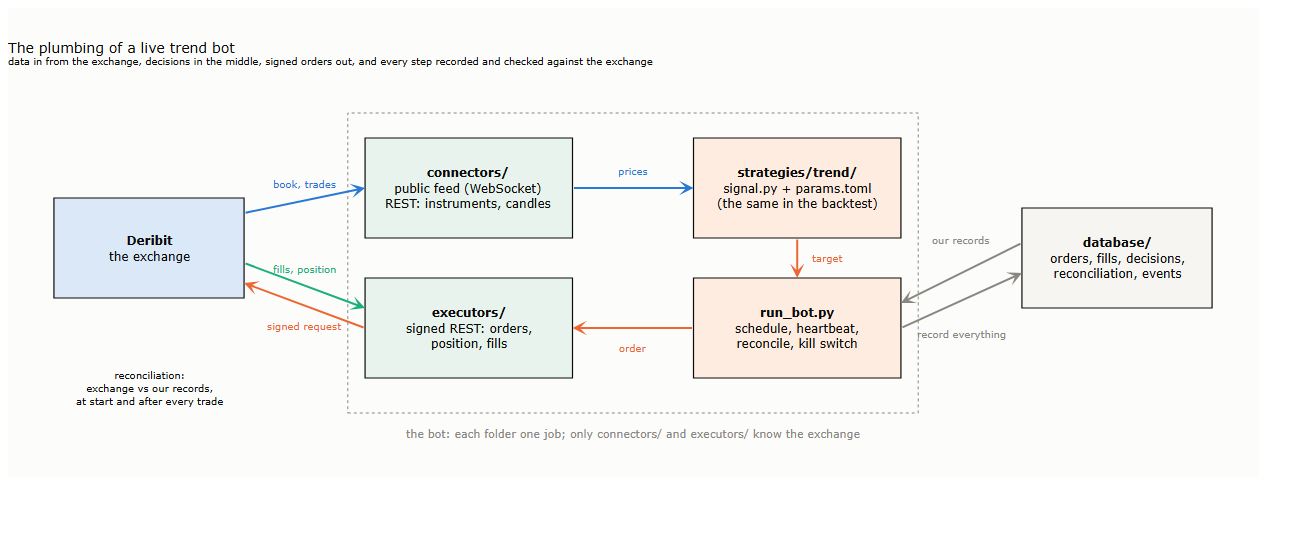

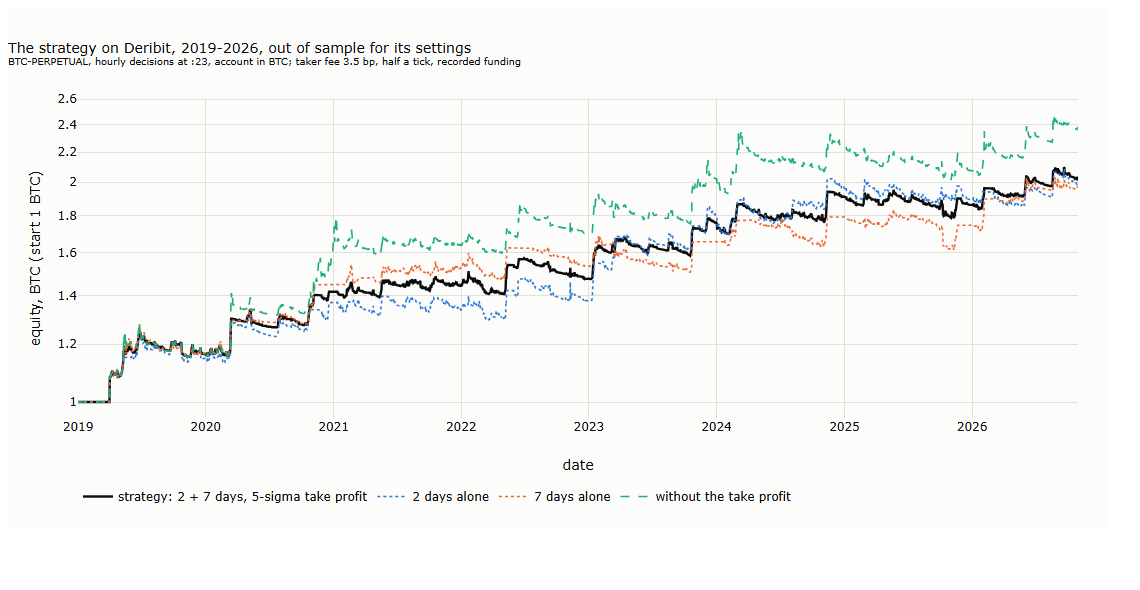

In [6]:
if HISTORY.exists():
    run("lectures/24-a-live-trend-bot/scripts/l24_charts.py")
    pictures("24_architecture", "24_backtest")
else:
    print("history missing: set RUN_ALL = True to download it; showing the lecture's figures")
    for nm in ("24_architecture", "24_backtest"): display(Image(filename=str(FIG / f"{nm}.png")))

## 5. Shipped against recomputed

With `RUN_ALL`, the rerun's key numbers against the shipped ones. With the same history they match exactly; Deribit's history does not change, but a later download adds months.

In [7]:
R = WORK / "backtest.json"
if R.exists():
    N = json.loads(R.read_text(encoding="utf-8"))
    display(pd.DataFrame({k: {"shipped": B["variants"][k]["sharpe"], "recomputed": N["variants"][k]["sharpe"]} for k in B["variants"]}).T.round(4))
else:
    print("nothing recomputed yet: set RUN_ALL = True")

nothing recomputed yet: set RUN_ALL = True


**A test of your own.** Change one setting in `capstone/strategies/trend/params.toml` (the speeds, the take-profit threshold, the decision minute) and rerun with `RUN_ALL`. As §9 says, write the change and its reason in `results/hypotheses.md` before looking at the result, and remember that every setting you try is one more try (toolkit card 8).